## 1. Installation

In [38]:
%pip install -q transformers torch pandas matplotlib seaborn requests tqdm ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [39]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import torch
from IPython.display import Markdown, display
from ipywidgets import Dropdown, interact
from tqdm.auto import tqdm
from transformers import pipeline

pd.set_option("display.max_colwidth", 160)
sns.set_theme(style="whitegrid")
print("PyTorch:", torch.__version__)
print("CUDA-GPU tilgængelig:", torch.cuda.is_available())

PyTorch: 2.14.0+cpu
CUDA-GPU tilgængelig: False


## 2. Hent Flatland

In [26]:
TEXT_URL = "https://www.gutenberg.org/cache/epub/97/pg97.txt"
TEXT_FILE = Path("flatland.txt")

if not TEXT_FILE.exists():
    response = requests.get(TEXT_URL, timeout=30)
    response.raise_for_status()
    TEXT_FILE.write_text(response.text, encoding="utf-8")

raw_text = TEXT_FILE.read_text(encoding="utf-8")
print(f"Indlæst {len(raw_text):,} tegn")
print(raw_text[:300])

Indlæst 217,416 tegn
The Project Gutenberg eBook of Flatland: A Romance of Many Dimensions

    

This eBook is for the use of anyone anywhere in the United States and

most other parts of the world at no cost and with almost no restrictions

whatsoever. You may copy it, give it away or re-use it under the terms

of the


## 3. Opdel bogen i 22 afsnit

In [33]:
def extract_book(text):
    start = text.find("§ 1 Of the Nature of Flatland")
    end = text.find("*** END OF THE PROJTEXT GUTENBERG EBOOK")
    if start == -1:
        raise ValueError("Kunne ikke finde første afsnit")
    return text[start:end if end != -1 else None]

def parse_sections(text):
    heading = re.compile(r"^§\s*(\d+)\s+(.+)$")
    records = []
    number = title = None
    buffer = []

    def save():
        nonlocal buffer
        if number is not None:
            body = "\n".join(buffer)
            body = re.sub(r"\[Illustration.*?\]", " ", body, flags=re.I | re.S)
            body = re.sub(r"[ \t]+", " ", body)
            body = re.sub(r"\n{3,}", "\n\n", body).strip()
            records.append({
                "section": number,
                "title": title.strip(),
                "part": "I - This World" if number <= 12 else "II - Other Worlds",
                "text": body,
            })
        buffer = []

    lines = text.splitlines()
    i = 0
    while i < len(lines):
        line = lines[i].strip()
        match = heading.match(line)
        if match:
            save()
            number, title = int(match.group(1)), match.group(2)
            # Længere overskrifter kan fortsætte på næste linje
            while i + 1 < len(lines) and lines[i + 1].strip():
                i += 1
                title += " " + lines[i].strip()
        elif number is not None:
            buffer.append(line)
        i += 1
    save()

    df = pd.DataFrame(records)
    df["word_count"] = df.text.str.split().str.len()
    return df
    
book_text = extract_book(raw_text)
sections = parse_sections(book_text)
print(f"Fandt {len(sections)} afsnit og {sections.word_count.sum():,} ord")
sections[["section", "part", "title", "word_count"]]

Fandt 22 afsnit og 36,175 ord


,section,part,title,word_count
0,1,I - This World,Of the Nature of Flatland,731
1,2,I - This World,Of the Climate and Houses in Flatland,807
2,3,I - This World,Concerning the Inhabitants of Flatland,1218
3,4,I - This World,Concerning the Women,1899
4,5,I - This World,Of our Methods of Recognizing one another,1763
5,6,I - This World,Of Recognition by Sight,1742
6,7,I - This World,Concerning Irregular Figures,1216
7,8,I - This World,Of the Ancient Practice of Painting,974
8,9,I - This World,Of the Universal Colour Bill,1293
9,10,I - This World,Of the Suppression of the Chromatic Sedition,1449


## 4. Del teksten i mindre passager

In [36]:
def make_passages(section_df, words_per_passage=120):
    rows = []
    passage_id = 1
    for section in section_df.itertuples():
        words = section.text.split()
        for start in range(0, len(words), words_per_passage):
            chunk = " ".join(words[start:start + words_per_passage])
            if len(chunk.split()) < 30:
                continue
            rows.append({
                "passage_id": passage_id,
                "section": section.section,
                "part": section.part,
                "title": section.title,
                "text": chunk,
            })
            passage_id += 1
    result = pd.DataFrame(rows)
    result["position"] = np.linspace(0, 100, len(result))
    result["word_count"] = result.text.str.split().str.len()
    return result

passages = make_passages(sections)
print(f"Oprettet {len(passages)} analysepassager")
passages.head()

Oprettet 307 analysepassager


,passage_id,section,part,title,text,position,word_count
0,1,1,I - This World,Of the Nature of Flatland,"I call our world Flatland, not because we call it so, but to make its nature clearer to you, my happy readers, who are privileged to live in Space. Imagine ...",0.000000,120
1,2,1,I - This World,Of the Nature of Flatland,you will perceive at once that it is impossible that there should be anything of what you call a “solid” kind; but I dare say you will suppose that we could...,0.326797,120
2,3,1,I - This World,Of the Nature of Flatland,"back to the edge of the table, gradually lower your eye (thus bringing yourself more and more into the condition of the inhabitants of Flatland), and you wi...",0.653595,120
3,4,1,I - This World,Of the Nature of Flatland,"look at it with your eye on the edge of the table, you will find that it ceases to appear to you as a figure, and that it becomes in appearance a straight l...",0.980392,120
4,5,1,I - This World,Of the Nature of Flatland,nothing but a straight line. When I was in Spaceland I heard that your sailors have very similar experiences while they traverse your seas and discern some ...,1.307190,120


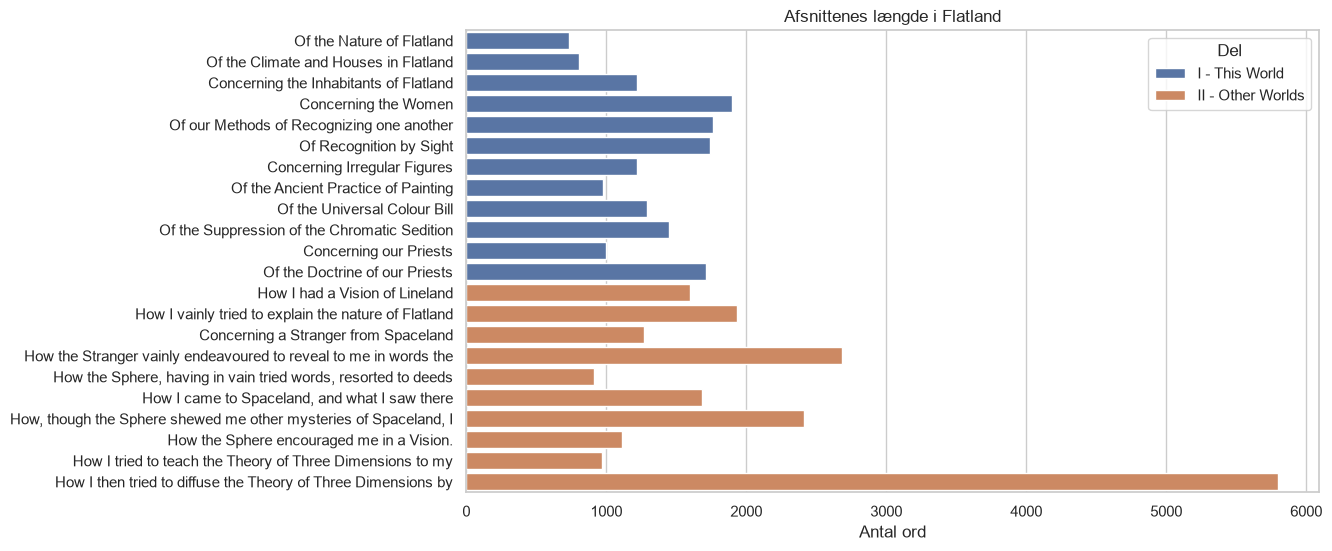

In [37]:
plt.figure(figsize=(11, 6))
sns.barplot(data=sections, x="word_count", y="title", hue="part", dodge=False)
plt.title("Afsnittenes længde i Flatland")
plt.xlabel("Antal ord")
plt.ylabel("")
plt.legend(title="Del")
plt.show()

## 5. Indlæs zero-shot-modellen

In [43]:
MODEL_NAME = "valhalla/distilbart-mnli-12-1"
classifier = pipeline(
    "zero-shot-classification",
    model=MODEL_NAME,
    device = 0 if torch.cuda.is_available() else -1,
)
print("Modellen er klar:", MODEL_NAME)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  890MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/231 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  890MB            

model.safetensors: downloading bytes:           |  0.00B            

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/772 [00:00<?, ?B/s]

Modellen er klar: valhalla/distilbart-mnli-12-1


## 6. Klassificér én passage

In [44]:
DEFAULT_THEMES = [
    "reality and perception",
    "knowledge and enlightenment",
    "social control",
    "freedom and rebellion",
    "conformity",
    "class hierarchy",
    "identity",
    "resistance to new ideas",
]

def classify_text(text, labels=DEFAULT_THEMES):
    shortened = " ".join(text.split()[:250])
    output = classifier(
        shortened,
        candidate_labels=list(labels),
        multi_label=True,
        hypothesis_template="This passage is about {}.",
    )
    return pd.DataFrame({"theme": output["labels"], "score": output["scores"]})


example = passages.query("section == 17").iloc[0]
display(Markdown(f"### §{example.section}: {example.title}"))
display(Markdown(f"> {example.text}"))
example_scores = classify_text(example.text)
display(example_scores.style.format({"score": "{:.1%}"}).bar(
    subset=["score"], vmin=0, vmax=1, color="#7a9cc6"
))

### §17: How the Sphere, having in vain tried words, resorted to deeds

> It was in vain. I brought my hardest right angle into violent collision with the Stranger, pressing on him with a force sufficient to have destroyed any ordinary Circle: but I could feel him slowly and unarrestably slipping from my contact; not edging to the right nor to the left, but moving somehow out of the world, and vanishing into nothing. Soon there was a blank. But still I heard the Intruder’s voice. _Sphere_. Why will you refuse to listen to reason? I had hoped to find in you—as being a man of sense and an accomplished mathematician—a fit apostle for the Gospel of the Three Dimensions, which I am allowed to preach once only in a thousand years: but

,theme,score
0,knowledge and enlightenment,16.3%
1,freedom and rebellion,7.1%
2,identity,5.6%
3,resistance to new ideas,5.3%
4,social control,4.7%
5,reality and perception,4.4%
6,conformity,3.2%
7,class hierarchy,2.5%


## 7. Interaktiv afsnitsanalyse

In [48]:
section_options = [
    (f"§{row.section}: {row.title}", int(row.section))
    for row in sections.itertuples()
]

def explore_section(section_number):
    choices = passages.query("section == @section_number").copy()
    choices["menu_text"] = choices.apply(
        lambda r: f"Passage {r.passage_id}: {r.text[:95]}...", axis=1
    )
    menu = Dropdown(
        options=[(r.menu_text, int(r.passage_id)) for _, r in choices.iterrows()],
        description="Passage:",
        layout={"width": "95%"},
    )

    def show(passage_id):
        row = passages.loc[passages.passage_id == passage_id].iloc[0]
        display(Markdown(f"### §{row.section}: {row.title}"))
        display(Markdown(f"> {row.text}"))
        result = classify_text(row.text)
        display(result.style.format({"score": "{:.1%}"}).bar(
            subset=["score"], vmin=0, vmax=1, color="#7a9cc6"
        ))

    interact(show, passage_id=menu)

interact(
    explore_section,
    section_number=Dropdown(options=section_options, value=15, description="Afsnit:"),
)

interactive(children=(Dropdown(description='Afsnit:', index=14, options=(('§1: Of the Nature of Flatland', 1),…

<function __main__.explore_section(section_number)>

## 8. Klassificér hele fortællingens udvikling

In [50]:
PASSAGES_PER_SECTION = 2
sample_parts = []
for _, group in passages.groupby("section"):
    indices = np.linspace(0, len(group) - 1, min(PASSAGES_PER_SECTION, len(group))).astype(int)
    sample_parts.append(group.iloc[indices])
sample = pd.concat(sample_parts, ignore_index=True).drop_duplicates("passage_id")


classified_rows = []
for row in tqdm(sample.itertuples(), total=len(sample)):
    result = classify_text(row.text)
    scores = dict(zip(result.theme, result.score))
    classified_rows.append({
        "passage_id": row.passage_id,
        "section": row.section,
        "part": row.part,
        "title": row.title,
        "position": row.position,
        "text": row.text,
        **scores,
    })

classified = pd.DataFrame(classified_rows)
classified.head()

  0%|          | 0/44 [00:00<?, ?it/s]

,passage_id,section,part,title,position,text,reality and perception,knowledge and enlightenment,identity,freedom and rebellion,resistance to new ideas,class hierarchy,social control,conformity
0,1,1,I - This World,Of the Nature of Flatland,0.000000,"I call our world Flatland, not because we call it so, but to make its nature clearer to you, my happy readers, who are privileged to live in Space. Imagine ...",0.296380,0.126438,0.108356,0.098223,0.054554,0.032830,0.024754,0.008752
1,6,1,I - This World,Of the Nature of Flatland,1.633987,"a kind as to make shadows, we have none of the helps to the sight that you have in Spaceland. If our friend comes closer to us we see his line becomes large...",0.386958,0.088040,0.321899,0.192730,0.138531,0.077608,0.179593,0.080952
2,7,2,I - This World,Of the Climate and Houses in Flatland,1.960784,"As with you, so also with us, there are four points of the compass North, South, East, and West. There being no sun nor other heavenly bodies, it is impossi...",0.262538,0.293326,0.184900,0.189438,0.117143,0.075180,0.052400,0.128148
3,13,2,I - This World,Of the Climate and Houses in Flatland,3.921569,"special tax. But, about three centuries afterwards, the Law decided that in all towns containing a population above ten thousand, the angle of a Pentagon wa...",0.400910,0.199932,0.338473,0.069299,0.115364,0.181238,0.450668,0.627207
4,14,3,I - This World,Concerning the Inhabitants of Flatland,4.248366,The greatest length or breadth of a full grown inhabitant of Flatland may be estimated at about eleven of your inches. Twelve inches may be regarded as a ma...,0.532339,0.432222,0.526168,0.299157,0.268934,0.591648,0.371031,0.460913


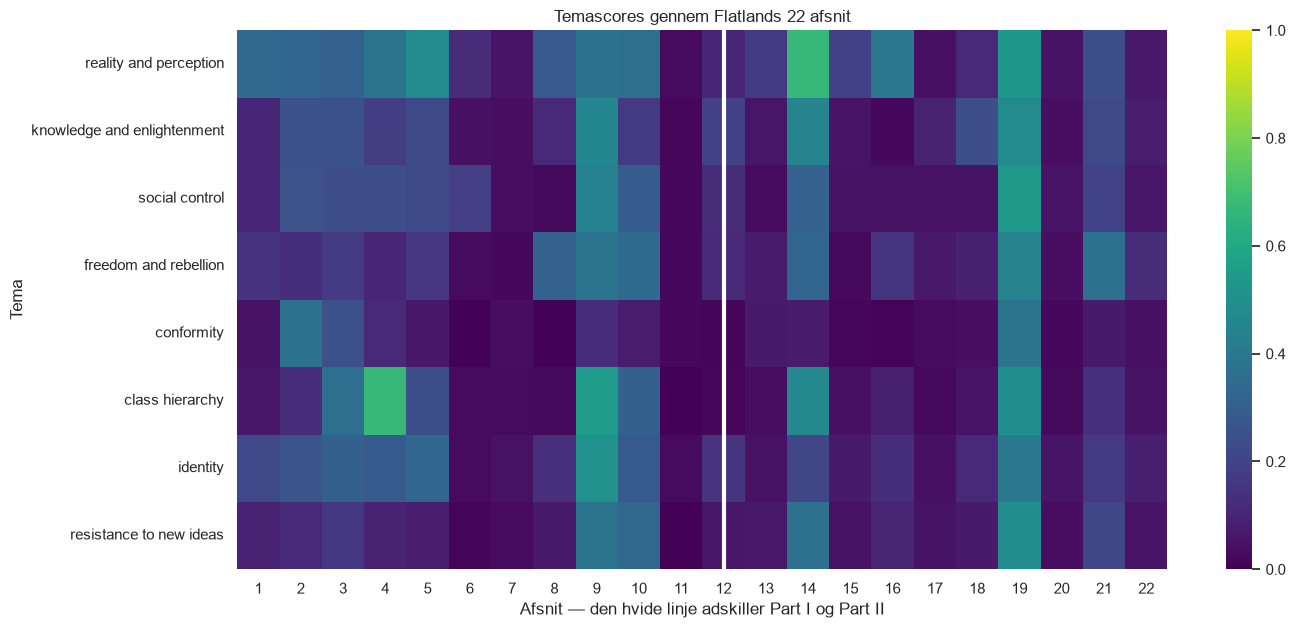

In [51]:
section_scores = classified.groupby("section")[DEFAULT_THEMES].mean()
plt.figure(figsize=(15, 7))
sns.heatmap(section_scores.T, cmap="viridis", vmin=0, vmax=1)
plt.axvline(11.5, color="white", linewidth=3)
plt.title("Temascores gennem Flatlands 22 afsnit")
plt.xlabel("Afsnit — den hvide linje adskiller Part I og Part II")
plt.ylabel("Tema")
plt.show()

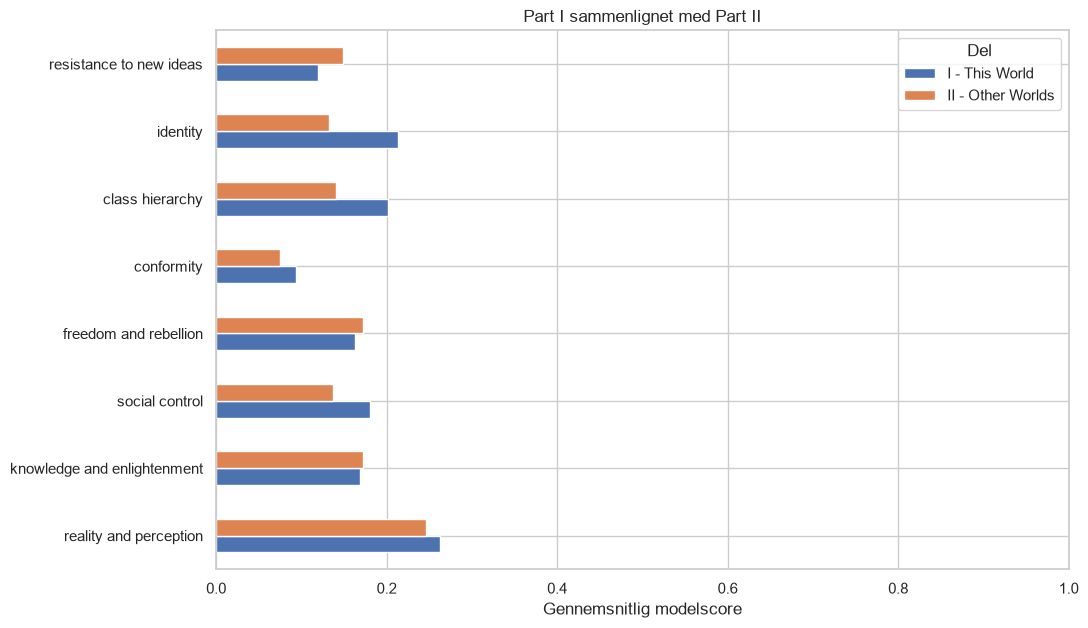

In [52]:
part_scores = classified.groupby("part")[DEFAULT_THEMES].mean().T
part_scores.plot(kind="barh", figsize=(11, 7))
plt.xlim(0, 1)
plt.title("Part I sammenlignet med Part II")
plt.xlabel("Gennemsnitlig modelscore")
plt.ylabel("")
plt.legend(title="Del")
plt.show()

## 9. Find tekstbeviserne

In [54]:
def strongest_passages(theme, n=5):
    columns = ["section", "title", "text", theme]
    return (
        classified[columns]
        .sort_values(theme, ascending=False)
        .head(n)
        .style.format({theme: "{:.1%}"})
    )

strongest_passages("reality and perception")

,section,title,text,reality and perception
26,14,How I vainly tried to explain the nature of Flatland,"Thinking that it was time to bring down the Monarch from his raptures to the level of common sense, I determined to endeavour to open up to him some glimpses of the truth, that is to say of the nature of things in Flatland. So I began thus: “How does your Royal Highness distinguish the shapes and positions of his subjects? I for my part noticed by the sense of sight, before I entered your Kingdom, that some of your people are lines and others Points; and that some of the lines are larger—” “You speak of an impossibility,” interrupted the King; “you must have seen a vision; for to detect the difference between a Line and a Point by",80.8%
37,19,"How, though the Sphere shewed me other mysteries of Spaceland, I","blame; but indeed I was intoxicated with the recent draughts of Truth to which he himself had introduced me. However, the end was not long in coming. My words were cut short by a crash outside, and a simultaneous crash inside me, which impelled me through space with a velocity that precluded speech. Down! down! down! I was rapidly descending; and I knew that return to Flatland was my doom. One glimpse, one last and never-to-be-forgotten glimpse I had of that dull level wilderness—which was now to become my Universe again—spread out before my eye. Then a darkness. Then a final, all-consummating thunder-peal; and, when I came to myself, I was once more a common creeping Square, in my Study",68.1%
18,10,Of the Suppression of the Chromatic Sedition,"The agitation for the Universal Colour Bill continued for three years; and up to the last moment of that period it seemed as though Anarchy were destined to triumph. A whole army of Polygons, who turned out to fight as private soldiers, was utterly annihilated by a superior force of Isosceles Triangles—the Squares and Pentagons meanwhile remaining neutral. Worse than all, some of the ablest Circles fell a prey to conjugal fury. Infuriated by political animosity, the wives in many a noble household wearied their lords with prayers to give up their opposition to the Colour Bill; and some, finding their entreaties fruitless, fell on and slaughtered their innocent children and husband, perishing themselves in the act of carnage. It",60.1%
31,16,How the Stranger vainly endeavoured to reveal to me in words the,"sides, that is to say, six of your insides. You see it all now, eh? “Monster,” I shrieked, “be thou juggler, enchanter, dream, or devil, no more will I endure thy mockeries. Either thou or I must perish.” And saying these words I precipitated myself upon him.",56.5%
8,5,Of our Methods of Recognizing one another,"You, who are blessed with shade as well as light, you, who are gifted with two eyes, endowed with a knowledge of perspective, and charmed with the enjoyment of various colours, you, who can actually _see_ an angle, and contemplate the complete circumference of a Circle in the happy region of the Three Dimensions—how shall I make it clear to you the extreme difficulty which we in Flatland experience in recognizing one another’s configuration? Recall what I told you above. All beings in Flatland, animate and inanimate, no matter what their form, present _to our view_ the same, or nearly the same, appearance, viz. that of a straight Line. How then can one be distinguished from another, where all appear",56.1%


## 10. Sammenlign med The Matrix

In [58]:
comparison = pd.DataFrame([
    {"Flatland": "Square", "The Matrix": "Neo", "Funktion": "Personen, hvis virkelighedsopfattelse bryder sammen"},
    {"Flatland": "Sphere", "The Matrix": "Morpheus", "Funktion": "Mentoren, der afslører en større virkelighed"},
    {"Flatland": "Spaceland", "The Matrix": "Den virkelige verden", "Funktion": "Virkelighed uden for den kendte verden"},
    {"Flatland": "Priests og Circles", "The Matrix": "Agents og maskiner", "Funktion": "Systemet, der beskytter den gældende orden"},
    {"Flatland": "Tredje dimension", "The Matrix": "Afsløringen af simulationen", "Funktion":
    "Viden, som ændrer alt"},
    ])
comparison

,Flatland,The Matrix,Funktion
0,Square,Neo,"Personen, hvis virkelighedsopfattelse bryder sammen"
1,Sphere,Morpheus,"Mentoren, der afslører en større virkelighed"
2,Spaceland,Den virkelige verden,Virkelighed uden for den kendte verden
3,Priests og Circles,Agents og maskiner,"Systemet, der beskytter den gældende orden"
4,Tredje dimension,Afsløringen af simulationen,"Viden, som ændrer alt"


11. Labels former resultaterne

In [59]:
passage = passages.query("section == 15").iloc[0].text
matrix_labels = ["awakening", "false reality", "mentor", "freedom"]
social_labels = ["class discrimination", "gender inequality", "authority", "conformity"]

display(Markdown(f"> {passage}"))
display(Markdown("### Matrix-inspirerede labels"), classify_text(passage, matrix_labels))
display(Markdown("### Samfundskritiske labels"), classify_text(passage, social_labels))

> From dreams I proceed to facts. It was the last day of our 1999th year of our era. The patterning of the rain had long ago announced nightfall; and I was sitting[1] in the company of my wife, musing on the events of the past and the prospects of the coming year, the coming century, the coming Millennium. [1] When I say “sitting,” of course I do not mean any change of attitude such as you in Spaceland signify by that word; for as we have no feet, we can no more “sit” nor “stand” (in your sense of the word) than one of your soles or flounders. Nevertheless, we perfectly well recognize the different mental states of volition implied

### Matrix-inspirerede labels

,theme,score
0,false reality,0.109453
1,freedom,0.038206
2,mentor,0.022609
3,awakening,0.012775


### Samfundskritiske labels

,theme,score
0,authority,0.098312
1,class discrimination,0.090017
2,gender inequality,0.072968
3,conformity,0.009652
